
# Northbridge University – Admissions Data Analysis

## Task 2: Construct a Programming Solution

### Introduction

This notebook presents a Python-based admissions data analysis solution for Northbridge University. It combines applicant records from Recruiter A and Recruiter B to examine historical admission outcomes, identify data-quality issues and generate meaningful business insights.

The analysis uses Python libraries, including Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

The notebook covers the following stages:

1. Loading and combining the two admissions datasets.
2. Inspecting and cleaning applicant records.
3. Performing descriptive statistical analysis.
4. Conducting exploratory data analysis (EDA).
5. Developing and evaluating predictive classification models.
6. Examining model performance across demographic groups.
7. Validating and exporting analytical results.
8. Saving trained model pipelines for future use.

The objective is to provide a reproducible and maintainable programming solution that supports evidence-based admissions analysis. Predictive results are interpreted as estimates of historical admission decisions rather than measures of future academic success.



PSEUDOCODE: NORTHBRIDGE UNIVERSITY ADMISSIONS ANALYSIS

BEGIN

STEP 1: IMPORT LIBRARIES
    Import required Python libraries

STEP 2: LOAD DATA
    Load and combine both recruiter datasets

STEP 3: CLEAN DATA
    Inspect, validate and handle missing and invalid values

STEP 4: PERFORM EDA
    Analyse admission outcomes, recruiter performance and applicant characteristics

STEP 5: BUILD MODELS
    Prepare features, split data and train both classifiers

STEP 6: EVALUATE AND AUDIT
    Compare model performance and assess demographic fairness

STEP 7: EXPORT RESULTS
    Validate predictions, export results and save trained models

STEP 8: REPORT FINDINGS
    Summarise results, limitations and recommendations

END



## 1. Import Required Libraries

The following Python libraries are used to load, manipulate, analyse, visualise and model the admissions datasets.

- **Pandas:** Loads CSV and Excel files, combines datasets, manages missing values and performs descriptive analysis.
- **NumPy:** Supports numerical calculations and missing-value handling.
- **Matplotlib:** Creates charts and visual representations of analytical findings.
- **Seaborn:** Produces statistical visualisations, including histograms, boxplots and heatmaps.
- **Scikit-learn:** Provides data preprocessing, train-test splitting, classification algorithms and model evaluation metrics.
- **Joblib:** Saves trained machine-learning pipelines for future use.

These libraries provide the main functionality required to develop a reproducible admissions analysis solution.


In [ ]:
# Import libraries for data analysis, visualisation and modelling

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from IPython.display import display
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Set a consistent visualisation style
sns.set_theme(style="whitegrid")

# Make displayed tables easier to read
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


### Upload the two datasets to Google Colab

This step uploads the Recruiter A CSV and Recruiter B Excel datasets into Google Colab. The files.upload() function allows users to select files from their computer. The uploaded filenames are displayed to confirm successful uploading before data loading and preparation.

In [ ]:
# Upload recruiter A and recruiter B datasets

from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving recruiter_A.csv to recruiter_A (2).csv
Saving recruiter_B.xlsx to recruiter_B (2).xlsx
Uploaded files:
recruiter_A (2).csv
recruiter_B (2).xlsx


### Load both datasets
Identifies the uploaded CSV and Excel files using their extensions. Pandas reads both datasets into separate DataFrames. The programme checks whether both files are available, displays their dimensions and previews the first five records.

In [ ]:
# Read the CSV and Excel files

csv_file = next(
    (f for f in uploaded if f.lower().endswith(".csv")),
    None
)

excel_file = next(
    (f for f in uploaded if f.lower().endswith((".xlsx", ".xls"))),
    None
)

if csv_file is None or excel_file is None:
    raise FileNotFoundError(
        "Please upload both a CSV file and an Excel file."
    )

recruiter_A = pd.read_csv(csv_file)
recruiter_B = pd.read_excel(excel_file)

print("Recruiter A shape:", recruiter_A.shape)
print("Recruiter B shape:", recruiter_B.shape)

print("\nRecruiter A preview:")
display(recruiter_A.head())

print("\nRecruiter B preview:")
display(recruiter_B.head())

Recruiter A shape: (4000, 12)
Recruiter B shape: (4000, 12)

Recruiter A preview:


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,NaN,1
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,NaN,1
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,NaN,1
3,A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,NaN,1
4,A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,NaN,1



Recruiter B preview:


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,B00001,61.3,76.1,3.80,State,Arts,95.6,0,Female,Other,NaN,0
1,B00002,56.6,60.9,2.81,State,Humanities,80.9,0,Female,Other,NaN,1
2,B00003,72.4,73.5,3.56,Independent,STEM,70.5,1,Male,White,NaN,1
3,B00004,76.3,75.4,2.46,State,Social Sciences,118.4,0,Male,Other,NaN,1
4,B00005,65.1,57.8,3.75,State,Humanities,88.3,1,Female,White,Learning,1


### Inspect column names and data types

The column names and data types of both datasets are examined to verify structural consistency. Matching column names are checked, and the column order is aligned to ensure both datasets have compatible structures before merging.

In [ ]:
# Check whether both datasets have compatible structures

print("Recruiter A columns:")
print(recruiter_A.columns.tolist())

print("\nRecruiter B columns:")
print(recruiter_B.columns.tolist())

print("\nRecruiter A data types:")
print(recruiter_A.dtypes)

print("\nRecruiter B data types:")
print(recruiter_B.dtypes)

if set(recruiter_A.columns) != set(recruiter_B.columns):
    raise ValueError(
        "The datasets have different column names. "
        "Investigate the differences before merging."
    )

# Align the column order
recruiter_B = recruiter_B[recruiter_A.columns]

print("\nDataset structures are compatible.")

Recruiter A columns:
['student_id', 'prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'first_generation_student', 'gender', 'ethnicity', 'disability_status', 'admission_outcome']

Recruiter B columns:
['student_id', 'prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'first_generation_student', 'gender', 'ethnicity', 'disability_status', 'admission_outcome']

Recruiter A data types:
student_id                   object
prior_attainment_score      float64
admissions_test_score       float64
personal_statement_score    float64
school_type                  object
intended_subject_area        object
distance_from_campus_km     float64
first_generation_student      int64
gender                       object
ethnicity                    object
disability_status            object
admission_outcome           

### Add recruiter identifiers and combine the data
Recruiter labels are added to distinguish the applicant records originating from each dataset. Both datasets are then combined vertically using Pandas concat(). The combined dataset is checked for its total records, dimensions and application counts by recruiter.

In [ ]:
# Preserve the origin of each applicant record

recruiter_A = recruiter_A.copy()
recruiter_B = recruiter_B.copy()

recruiter_A["recruiter"] = "Recruiter A"
recruiter_B["recruiter"] = "Recruiter B"

# Combine both datasets vertically
df = pd.concat(
    [recruiter_A, recruiter_B],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)
print("Total applications:", len(df))

print("\nApplications by recruiter:")
display(df["recruiter"].value_counts().rename("applications"))

display(df.head())

Combined dataset shape: (8000, 13)
Total applications: 8000

Applications by recruiter:


,applications
recruiter,
Recruiter A,4000
Recruiter B,4000


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome,recruiter
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,NaN,1,Recruiter A
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,NaN,1,Recruiter A
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,NaN,1,Recruiter A
3,A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,NaN,1,Recruiter A
4,A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,NaN,1,Recruiter A


### Check missing values, duplicates and unique IDs
Missing values and their percentages are examined to identify incomplete records. Duplicate rows and applicant IDs are checked to ensure data consistency. Records by recruiter and admission outcome counts are also reviewed to assess dataset quality before cleaning.

In [ ]:
# Conduct initial data-quality checks

print("Missing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nMissing-value percentages:")
display(
    (df.isnull().mean() * 100)
    .round(2)
    .to_frame("missing_percentage")
)

print("\nFull duplicate rows:", df.duplicated().sum())

print("Duplicate applicant IDs:", df["student_id"].duplicated().sum())

print("\nRecords by recruiter:")
display(df["recruiter"].value_counts())

print("\nTarget variable counts:")
display(df["admission_outcome"].value_counts(dropna=False))

Missing values by column:


,missing_values
student_id,0
prior_attainment_score,0
admissions_test_score,0
personal_statement_score,0
school_type,1
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0



Missing-value percentages:


,missing_percentage
student_id,0.00
prior_attainment_score,0.00
admissions_test_score,0.00
personal_statement_score,0.00
school_type,0.01
intended_subject_area,0.01
distance_from_campus_km,0.01
first_generation_student,0.00
gender,0.00
ethnicity,0.00



Full duplicate rows: 0
Duplicate applicant IDs: 0

Records by recruiter:


,count
recruiter,
Recruiter A,4000
Recruiter B,4000



Target variable counts:


,count
admission_outcome,
1,4850
0,3150


### Clean identifiers and validate target values

Applicant IDs are standardised by removing unnecessary spaces and converting them into string format. Missing and duplicate IDs are checked to maintain record uniqueness. The admission outcome is validated to ensure binary values (0 and 1) before preparing the dataset for predictive modelling.

In [ ]:
# Standardise identifier formatting and validate key fields

df["student_id"] = df["student_id"].astype("string").str.strip()

# Check whether IDs are missing or duplicated
if df["student_id"].isna().any():
    raise ValueError("Missing student IDs must be investigated.")

if df["student_id"].duplicated().any():
    raise ValueError(
        "Duplicate student IDs detected. Investigate before modelling."
    )

# Validate the binary target variable
valid_target = df["admission_outcome"].isin([0, 1])

if not valid_target.all():
    print("Invalid target records:")
    display(df.loc[~valid_target])

    # Exclude records with invalid target labels from supervised modelling
    df = df.loc[valid_target].copy()

df["admission_outcome"] = df["admission_outcome"].astype(int)

print("Unique applicant IDs:", df["student_id"].nunique())
print("Records available for analysis:", len(df))
print("Target validation completed.")

Unique applicant IDs: 8000
Records available for analysis: 8000
Target validation completed.


## Data cleaning and validation

The datasets are cleaned and validated to ensure accuracy, consistency and reliability before analysis. This involves identifying missing values, duplicate records, invalid numerical measurements and inconsistent categorical entries. Applicant identifiers and admission outcomes are also checked to maintain data integrity and support reliable analysis.

### Inspect unexpected category values
Categorical variables, including school type, intended subject area, gender, ethnicity and disability status, are examined to identify inconsistent labels, abbreviations and missing entries. Category frequencies are displayed to identify unexpected values requiring standardisation before conducting further analysis.

In [ ]:
# Inspect categorical variables before standardisation

categorical_columns = [
    "school_type",
    "intended_subject_area",
    "gender",
    "ethnicity",
    "disability_status"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


school_type:
school_type
State            5205
Independent      1957
International     834
S                   2
I                   1
NaN                 1
Name: count, dtype: int64

intended_subject_area:
intended_subject_area
Social Sciences    2019
STEM               1997
Arts               1992
Humanities         1989
Soc                   1
A                     1
NaN                   1
Name: count, dtype: int64

gender:
gender
Female    4026
Male      3806
Other      164
M            2
F            2
Name: count, dtype: int64

ethnicity:
ethnicity
Other    1633
Mixed    1614
Asian    1597
Black    1593
White    1563
Name: count, dtype: int64

disability_status:
disability_status
NaN         6210
Learning     807
Mental       492
Physical     491
Name: count, dtype: int64


### Standardise categorical values

Inconsistent categorical entries are standardised by replacing recognised abbreviations with their corresponding full labels. Leading and trailing spaces are also removed to maintain consistency. Updated category frequencies are displayed to verify the changes and identify any remaining inconsistencies.

In [ ]:
# Review Cell 8 first. Do not map an abbreviation if its meaning is uncertain.

category_mappings = {
    "school_type": {
        "S": "State",
        "I": "Independent"
    },
    "intended_subject_area": {
        "Soc": "Social Sciences",
        "A": "Arts"
    },
    "gender": {
        "M": "Male",
        "F": "Female"
    },
    "disability_status": {
        "Mental": "Mental Health"
    }
}

for column, mapping in category_mappings.items():
    df[column] = df[column].replace(mapping)

# Remove leading/trailing spaces in categorical fields
for column in categorical_columns:
    df[column] = df[column].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Category standardisation completed.")

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

Category standardisation completed.

school_type:
school_type
State            5207
Independent      1958
International     834
NaN                 1
Name: count, dtype: int64

intended_subject_area:
intended_subject_area
Social Sciences    2020
STEM               1997
Arts               1993
Humanities         1989
NaN                   1
Name: count, dtype: int64

gender:
gender
Female    4028
Male      3808
Other      164
Name: count, dtype: int64

ethnicity:
ethnicity
Other    1633
Mixed    1614
Asian    1597
Black    1593
White    1563
Name: count, dtype: int64

disability_status:
disability_status
NaN              6210
Learning          807
Mental Health     492
Physical          491
Name: count, dtype: int64


### Validate numerical ranges
Numerical variables are examined against their expected ranges to identify invalid measurements. Prior attainment and admissions test scores are checked against the 0–100 scale, personal statement scores against the 1–5 scale, and campus distances for negative values. Any out-of-range records are displayed for investigation.

In [ ]:
# Identify numerical values outside expected ranges

expected_ranges = {
    "prior_attainment_score": (0, 100),
    "admissions_test_score": (0, 100),
    "personal_statement_score": (1, 5),
    "distance_from_campus_km": (0, None)
}

for column, (lower, upper) in expected_ranges.items():

    invalid = pd.Series(False, index=df.index)

    if lower is not None:
        invalid |= df[column].notna() & (df[column] < lower)

    if upper is not None:
        invalid |= df[column].notna() & (df[column] > upper)

    print(f"\n{column}: {invalid.sum()} out-of-range records")

    if invalid.any():
        display(
            df.loc[invalid, ["student_id", "recruiter", column]].head(20)
        )


prior_attainment_score: 4 out-of-range records


,student_id,recruiter,prior_attainment_score
731,A00732,Recruiter A,105.7
3640,A03641,Recruiter A,100.5
4328,B00329,Recruiter B,100.8
6550,B02551,Recruiter B,103.5



admissions_test_score: 10 out-of-range records


,student_id,recruiter,admissions_test_score
731,A00732,Recruiter A,101.5
2386,A02387,Recruiter A,101.0
2702,A02703,Recruiter A,100.1
3558,A03559,Recruiter A,104.7
4806,B00807,Recruiter B,101.0
5441,B01442,Recruiter B,101.3
5629,B01630,Recruiter B,100.2
5673,B01674,Recruiter B,101.0
5987,B01988,Recruiter B,100.4
7839,B03840,Recruiter B,100.5



personal_statement_score: 133 out-of-range records


,student_id,recruiter,personal_statement_score
83,A00084,Recruiter A,5.06
173,A00174,Recruiter A,5.38
209,A00210,Recruiter A,5.45
252,A00253,Recruiter A,5.36
287,A00288,Recruiter A,6.45
304,A00305,Recruiter A,5.25
329,A00330,Recruiter A,5.43
384,A00385,Recruiter A,5.12
392,A00393,Recruiter A,0.87
420,A00421,Recruiter A,5.02



distance_from_campus_km: 0 out-of-range records


### Correct invalid numerical entries without inventing values
The dataset is prepared for descriptive analysis by removing exact duplicate records and applications with missing admission outcomes. The binary target is validated to retain only 0 and 1 values. Applicant IDs are standardised and checked for missing or duplicate identifiers. Finally, the cleaned dataset is reviewed for remaining missing values, target distribution and historical offer rate.

In [ ]:

# Prepare the cleaned dataset for descriptive analysis

# Step 1: Remove exact duplicate records
df = df.drop_duplicates().copy()

# Step 2: Remove records without a valid target outcome
target = "admission_outcome"

df = df.dropna(subset=[target]).copy()

# Step 3: Validate the binary admission outcome
valid_target = df[target].isin([0, 1])

if not valid_target.all():

    print("Invalid target records identified:")
    display(df.loc[~valid_target])

    df = df.loc[valid_target].copy()

# Convert target to integer
df[target] = df[target].astype(int)

# Step 4: Check applicant identifiers
df["student_id"] = (
    df["student_id"]
    .astype("string")
    .str.strip()
)

if df["student_id"].isna().any():
    raise ValueError("Missing applicant IDs detected.")

if df["student_id"].duplicated().any():
    raise ValueError("Duplicate applicant IDs detected.")

# Step 5: Display cleaned dataset information
print("Cleaned analysis dataset shape:", df.shape)

print("\nUnique applicant IDs:", df["student_id"].nunique())

print("\nRemaining missing values:")
display(
    df.isnull()
    .sum()
    .to_frame("missing_values")
)

print("\nTarget distribution:")
display(df[target].value_counts())

print("\nHistorical offer rate:")
print(f"{df[target].mean() * 100:.2f}%")


Cleaned analysis dataset shape: (8000, 21)

Unique applicant IDs: 8000

Remaining missing values:


,missing_values
student_id,0
prior_attainment_score,4
admissions_test_score,10
personal_statement_score,133
school_type,1
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0



Target distribution:


,count
admission_outcome,
1,4850
0,3150



Historical offer rate:
60.62%


### Examine outliers using boxplots

Boxplots are generated for each numerical variable to identify potential outliers and understand the spread of applicant data. The visualisations highlight the median, interquartile range and unusually high or low values. These observations support data-quality assessment without automatically removing valid records.

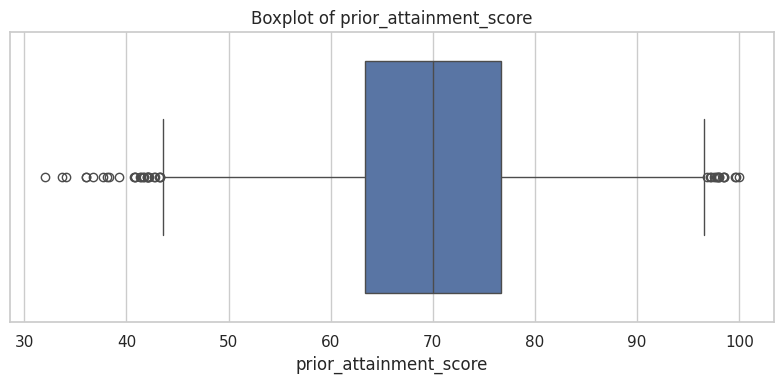

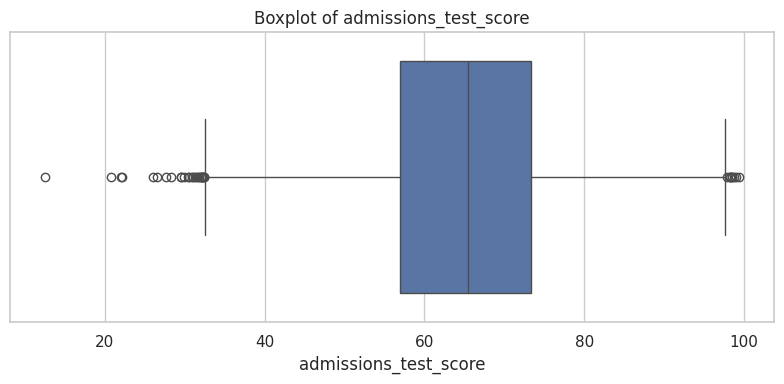

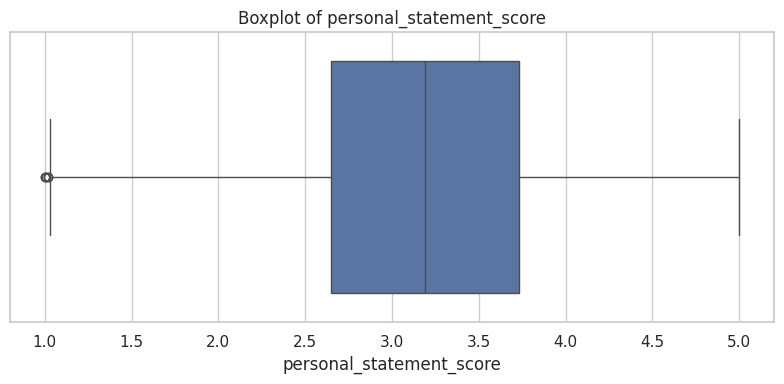

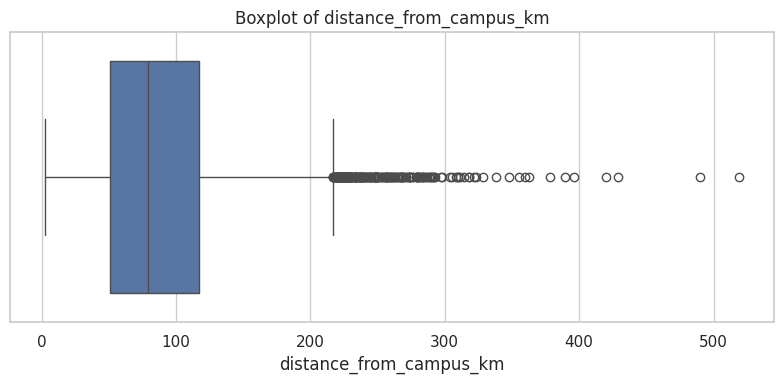

In [ ]:
# Visualise the numerical distributions and potential outliers

numerical_columns = [
    "prior_attainment_score",
    "admissions_test_score",
    "personal_statement_score",
    "distance_from_campus_km"
]

for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

### Prepare a cleaned modelling dataset

The dataset is prepared for predictive modelling by removing exact duplicate records and excluding applications with missing admission outcomes. The admission outcome is retained as the target variable. Missing values are checked, and the target distribution and historical offer rate are displayed to confirm the dataset is suitable for further modelling.

In [ ]:
# Create a modelling copy after quality checks

# Remove exact duplicate rows if any exist.
# Applicant IDs must remain unique; conflicting duplicate IDs need investigation.
df = df.drop_duplicates().copy()

# Preserve the historical offer outcome as the target
target = "admission_outcome"

# Confirm the target has no missing values
df = df.dropna(subset=[target]).copy()

print("Cleaned analysis dataset shape:", df.shape)
print("\nMissing values after initial cleaning:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nTarget distribution:")
display(df[target].value_counts())

print("\nOverall historical offer rate:")
print(f"{df[target].mean() * 100:.2f}%")

Cleaned analysis dataset shape: (8000, 21)

Missing values after initial cleaning:


,missing_values
student_id,0
prior_attainment_score,4
admissions_test_score,10
personal_statement_score,133
school_type,1
intended_subject_area,1
distance_from_campus_km,1
first_generation_student,0
gender,0
ethnicity,0



Target distribution:


,count
admission_outcome,
1,4850
0,3150



Overall historical offer rate:
60.62%


## Exploratory data analysis (EDA)
Exploratory Data Analysis (EDA) is conducted to examine the cleaned admissions dataset, identify important patterns and understand applicant characteristics. Statistical summaries, comparisons and visualisations are used to explore admission outcomes, recruiter performance and relationships between numerical and categorical variables

### Number of records
Calculates the total number of application records and unique student IDs in the combined dataset. Applications are grouped by recruiter to identify the number of applicants handled by each recruiter. A bar chart illustrates the distribution of applications and supports comparisons of recruitment activity.

Total records: 8000
Unique student IDs: 8000


,Recruiter,Applications
0,Recruiter A,4000
1,Recruiter B,4000


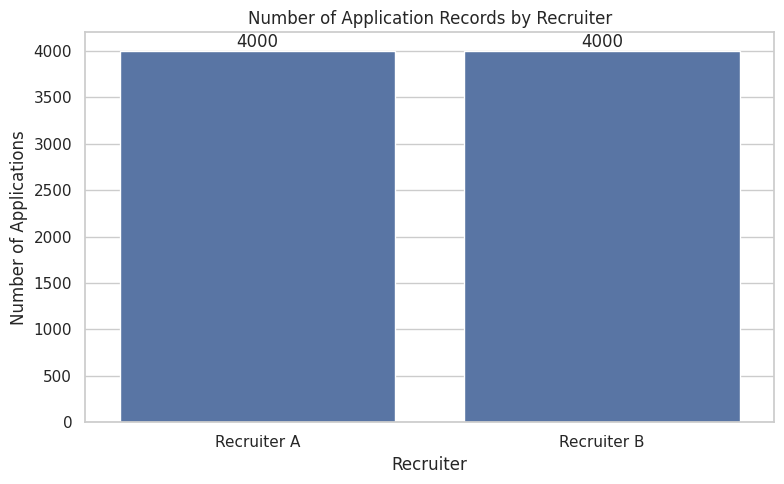

In [ ]:
# EDA 1: Number of records and applications by recruiter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

total_records = len(df)
unique_students = df["student_id"].nunique()

print("Total records:", total_records)
print("Unique student IDs:", unique_students)

recruiter_counts = (
    df["recruiter"]
    .value_counts()
    .rename_axis("Recruiter")
    .reset_index(name="Applications")
)

display(recruiter_counts)

# Graph: Number of records by recruiter
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=recruiter_counts,
    x="Recruiter",
    y="Applications"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Number of Application Records by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

### Percentage of students offered a place
The overall admission outcomes by calculating the total number of applications, offers and rejections. The historical offer percentage is calculated to identify the proportion of applicants who received a university place. A bar chart compares offers and non-offers, while a pie chart illustrates their percentage distribution, providing an overview of the university's admission outcomes.

Total applications: 8000
Offers: 4850
No offers: 3150
Offer percentage: 60.62%


,Outcome,Applications
0,Offer,4850
1,No offer,3150


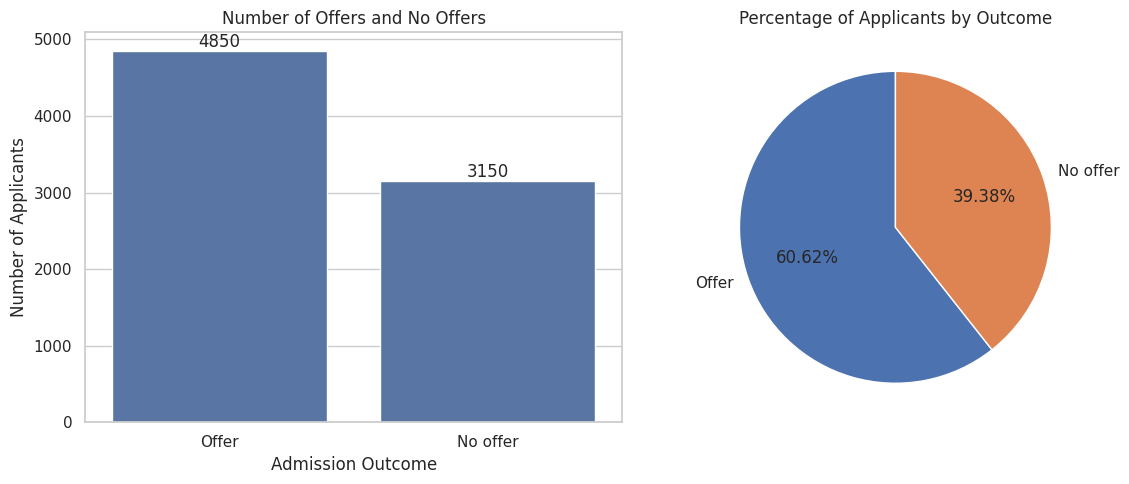

In [ ]:
# EDA 2: Overall admission outcomes

outcomes = df["admission_outcome"].dropna()

total_applications = len(outcomes)
total_offers = (outcomes == 1).sum()
total_rejections = (outcomes == 0).sum()

offer_percentage = (
    total_offers / total_applications * 100
    if total_applications > 0 else 0
)

print("Total applications:", total_applications)
print("Offers:", total_offers)
print("No offers:", total_rejections)
print(f"Offer percentage: {offer_percentage:.2f}%")

outcome_summary = pd.DataFrame({
    "Outcome": ["Offer", "No offer"],
    "Applications": [total_offers, total_rejections]
})

display(outcome_summary)

# Graph: Overall admission outcomes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=outcome_summary,
    x="Outcome",
    y="Applications",
    ax=axes[0]
)

axes[0].set_title("Number of Offers and No Offers")
axes[0].set_xlabel("Admission Outcome")
axes[0].set_ylabel("Number of Applicants")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

axes[1].pie(
    outcome_summary["Applications"],
    labels=outcome_summary["Outcome"],
    autopct="%1.2f%%",
    startangle=90
)

axes[1].set_title("Percentage of Applicants by Outcome")

plt.tight_layout()
plt.show()

### Comparison of Places Offered by Gender
Gender-based admission outcomes are examined by comparing the number of applications, offers and non-offers across different gender groups. The offer rate is calculated for each group to identify variations in historical admission decisions. Bar charts illustrate the distribution of offers and non-offers and the corresponding offer percentages, highlighting potential differences between groups.

Admission outcomes by gender:


,gender,applications,offers,offer_rate,no_offers
0,Female,4028,2453,60.90,1575
1,Male,3808,2307,60.58,1501
2,Other,164,90,54.88,74


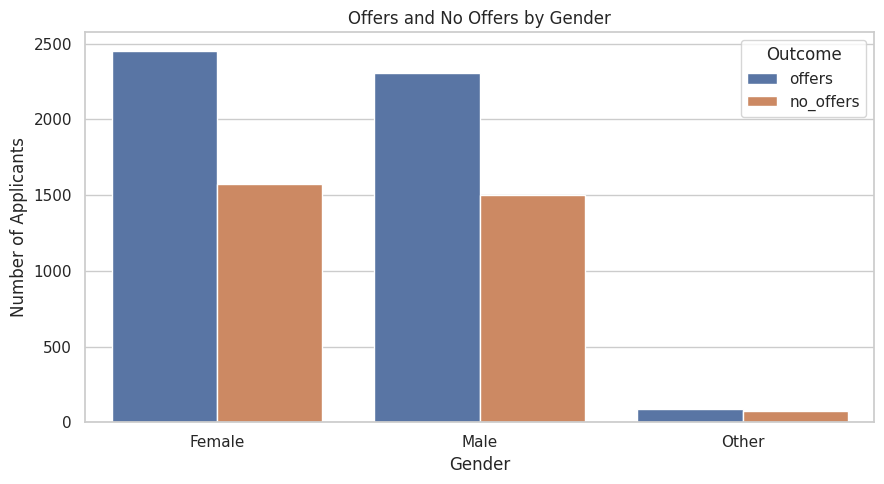

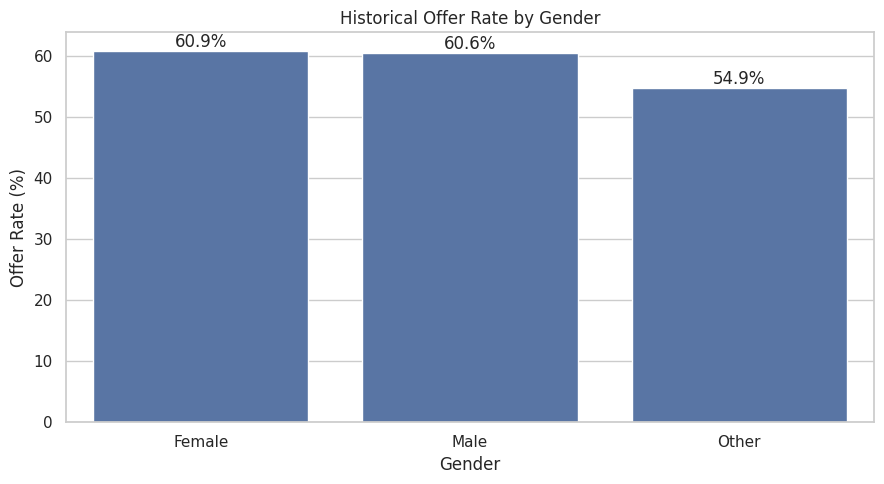

In [ ]:
# EDA 3: Applications and offers by gender

gender_outcomes = (
    df.groupby("gender", dropna=False)["admission_outcome"]
    .agg(
        applications="count",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

gender_outcomes["no_offers"] = (
    gender_outcomes["applications"] - gender_outcomes["offers"]
)

gender_outcomes["offer_rate"] *= 100

print("Admission outcomes by gender:")
display(gender_outcomes.round(2))

# Graph 1: Number of offers and no offers by gender
gender_plot = gender_outcomes.melt(
    id_vars="gender",
    value_vars=["offers", "no_offers"],
    var_name="Outcome",
    value_name="Applications"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=gender_plot,
    x="gender",
    y="Applications",
    hue="Outcome"
)

plt.title("Offers and No Offers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

# Graph 2: Offer rate by gender
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=gender_outcomes,
    x="gender",
    y="offer_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Historical Offer Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Offer Rate (%)")
plt.tight_layout()
plt.show()

### Number of applications by recruiter
The total number of applications received by each recruiter is calculated using Pandas grouping functions. The results are presented in a summary table and bar chart, allowing comparison of application volumes and identifying the distribution of applicant records between Recruiter A and Recruiter B.

,recruiter,number_of_applications
0,Recruiter A,4000
1,Recruiter B,4000


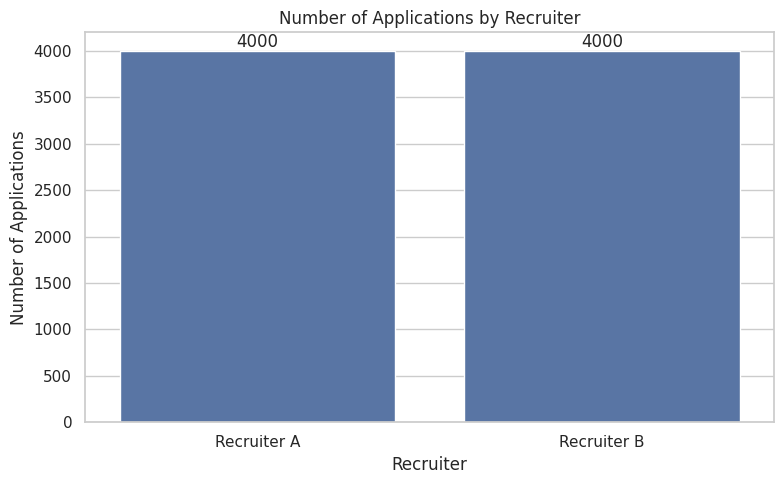

In [ ]:
# EDA 4: Application count for each recruiter

recruiter_applications = (
    df.groupby("recruiter")
    .size()
    .reset_index(name="number_of_applications")
)

display(recruiter_applications)

# Graph: Applications by recruiter
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=recruiter_applications,
    x="recruiter",
    y="number_of_applications"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Number of Applications by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

### Overall offer rate by recruiter
The distribution of applications is examined by grouping applicant records according to their assigned recruiters. The total number of applications handled by each recruiter is calculated and presented in a summary table. A bar chart visualises the application volumes, enabling comparison of recruiter workloads and their contribution to the university's admissions process.

Recruiter offer rates:


,recruiter,applications,offers,offer_rate,no_offers
0,Recruiter A,4000,2395,59.88,1605
1,Recruiter B,4000,2455,61.38,1545


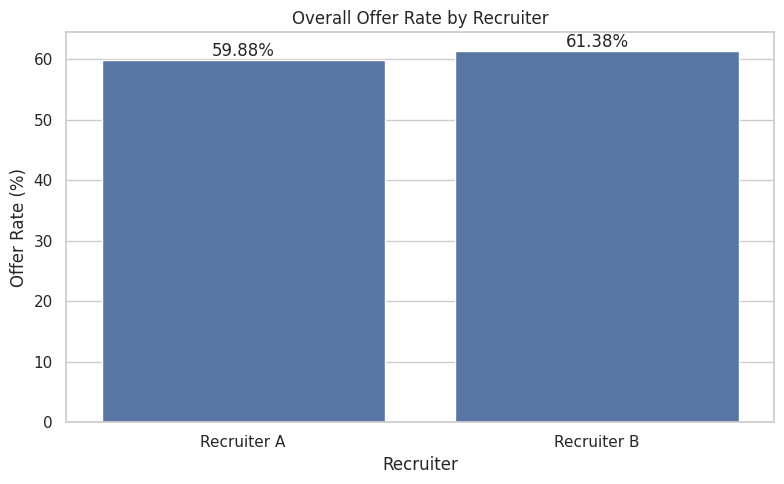

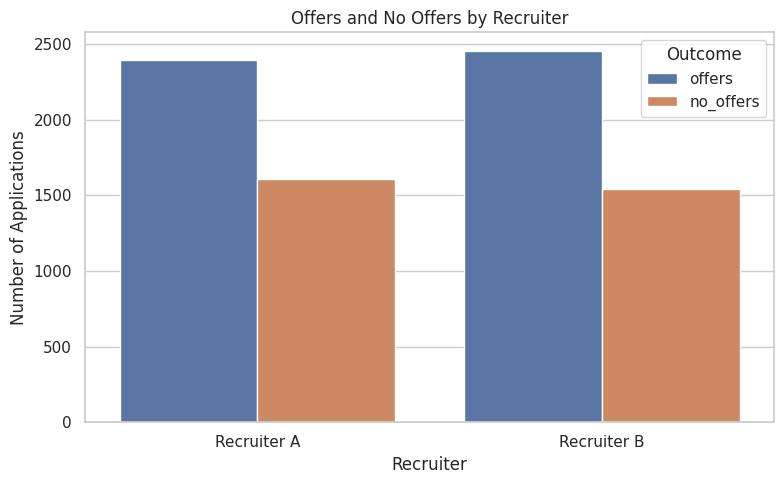

In [ ]:
# EDA 5: Calculate offer rate by recruiter

recruiter_offer_rates = (
    df.groupby("recruiter")["admission_outcome"]
    .agg(
        applications="count",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

recruiter_offer_rates["no_offers"] = (
    recruiter_offer_rates["applications"]
    - recruiter_offer_rates["offers"]
)

recruiter_offer_rates["offer_rate"] *= 100

print("Recruiter offer rates:")
display(recruiter_offer_rates.round(2))

# Graph 1: Historical offer rate by recruiter
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=recruiter_offer_rates,
    x="recruiter",
    y="offer_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Overall Offer Rate by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Offer Rate (%)")
plt.tight_layout()
plt.show()

# Graph 2: Offers and no offers by recruiter
recruiter_outcomes_plot = recruiter_offer_rates.melt(
    id_vars="recruiter",
    value_vars=["offers", "no_offers"],
    var_name="Outcome",
    value_name="Applications"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=recruiter_outcomes_plot,
    x="recruiter",
    y="Applications",
    hue="Outcome"
)

plt.title("Offers and No Offers by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Number of Applications")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

### Mean and median for the required numerical variables
Descriptive statistics are calculated for prior attainment scores, admissions test scores and distance from campus. The mean and median values provide an understanding of the central tendency of each variable. A comparative bar chart presents both measures, helping identify differences in numerical distributions and potential effects of extreme values.

Mean and median:


,Mean,Median
prior_attainment_score,70.00,70.0
admissions_test_score,65.12,65.4
distance_from_campus_km,89.53,79.5


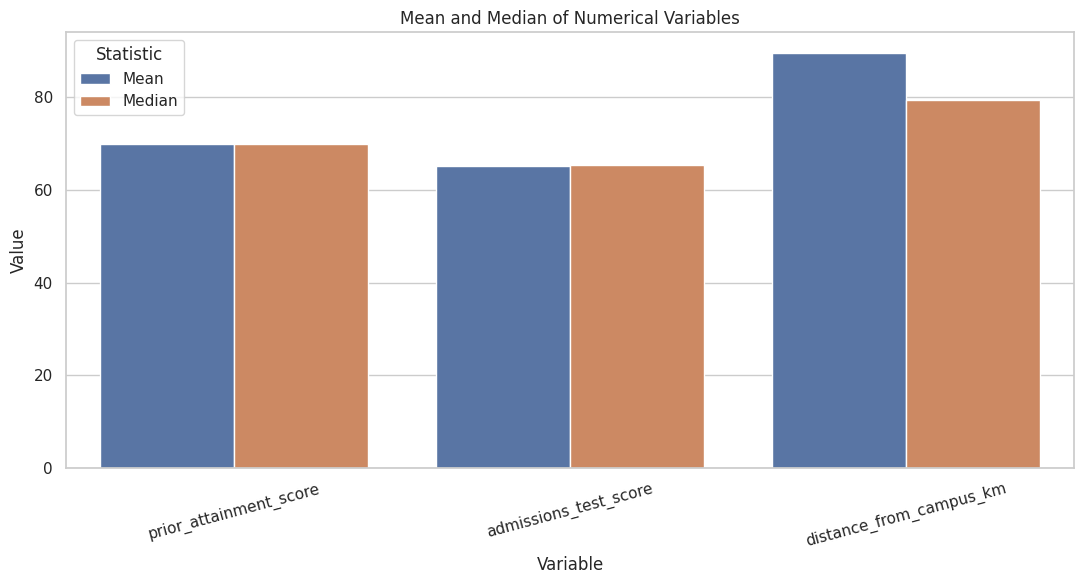

In [ ]:
# EDA 6: Mean and median statistics

required_columns = [
    "prior_attainment_score",
    "admissions_test_score",
    "distance_from_campus_km"
]

descriptive_statistics = pd.DataFrame({
    "Mean": df[required_columns].mean(),
    "Median": df[required_columns].median()
})

print("Mean and median:")
display(descriptive_statistics.round(2))

# Graph: Compare mean and median
statistics_plot = (
    descriptive_statistics
    .reset_index(names="Variable")
    .melt(
        id_vars="Variable",
        var_name="Statistic",
        value_name="Value"
    )
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=statistics_plot,
    x="Variable",
    y="Value",
    hue="Statistic"
)

plt.title("Mean and Median of Numerical Variables")
plt.xlabel("Variable")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.legend(title="Statistic")
plt.tight_layout()
plt.show()

### Distribution of numerical variables

The distributions of prior attainment scores, admissions test scores and distance from campus are examined using histograms and boxplots. Histograms illustrate the frequency and shape of each numerical variable, while boxplots highlight the median, spread and potential outliers. These visualisations help identify distribution patterns, skewness and unusual observations within the applicant dataset.

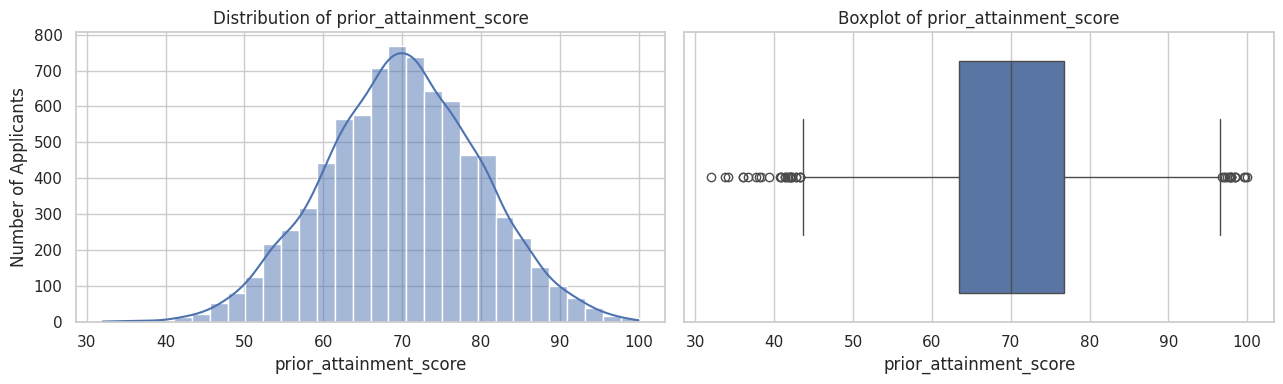

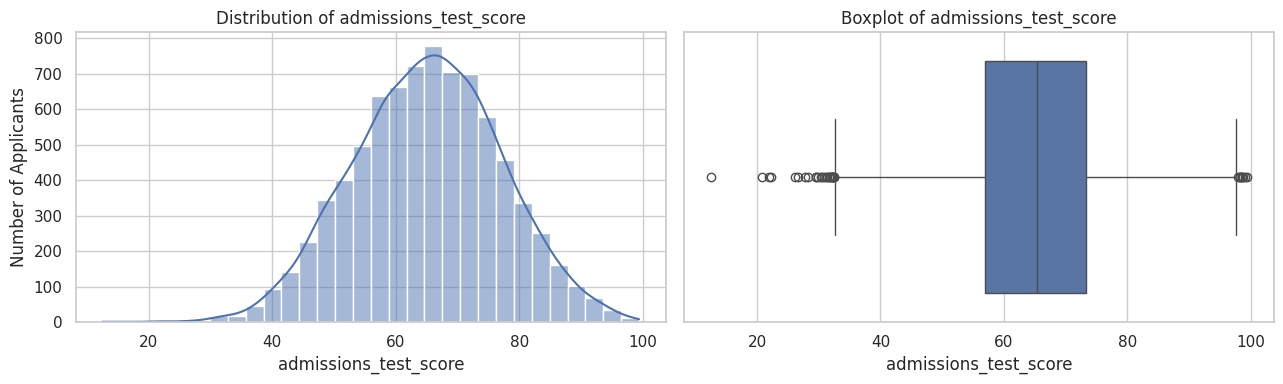

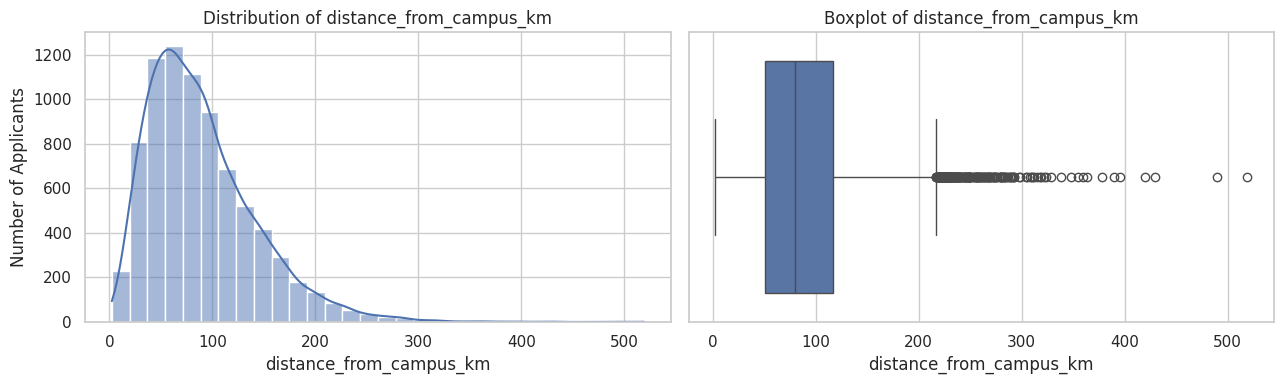

In [ ]:
# EDA 7: Histograms and boxplots for the required variables

for column in required_columns:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4)
    )

    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Number of Applicants")

    sns.boxplot(
        data=df,
        x=column,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {column}")
    axes[1].set_xlabel(column)

    plt.tight_layout()
    plt.show()

### Relationship between prior attainment and admissions test scores

The relationship between prior attainment and admissions test scores is examined using Pearson correlation. A scatterplot with a trend line and correlation heatmap visualise the strength and direction of the association, helping identify whether applicants' previous academic performance is related to their admissions test results.

Pearson correlation coefficient: 0.014


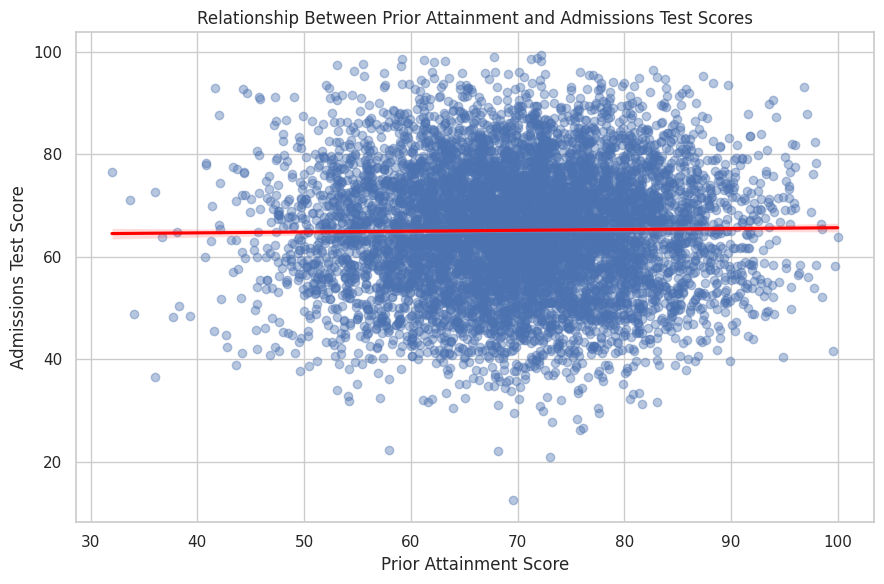

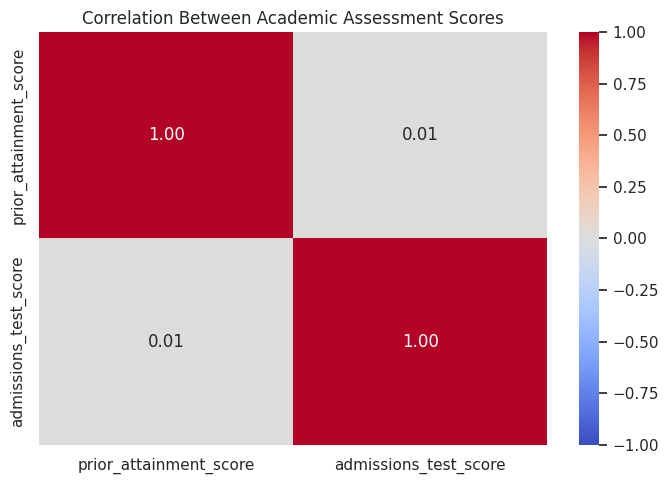

In [ ]:
# EDA 8: Relationship between academic scores

relationship_data = df[
    [
        "prior_attainment_score",
        "admissions_test_score"
    ]
].dropna()

correlation = relationship_data[
    "prior_attainment_score"
].corr(
    relationship_data["admissions_test_score"]
)

print(
    "Pearson correlation coefficient:",
    round(correlation, 3)
)

# Graph 1: Scatterplot with trend line
plt.figure(figsize=(9, 6))

sns.regplot(
    data=relationship_data,
    x="prior_attainment_score",
    y="admissions_test_score",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Prior Attainment and Admissions Test Scores")
plt.xlabel("Prior Attainment Score")
plt.ylabel("Admissions Test Score")
plt.tight_layout()
plt.show()

# Graph 2: Correlation heatmap
plt.figure(figsize=(7, 5))

correlation_matrix = relationship_data.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Academic Assessment Scores")
plt.tight_layout()
plt.show()

### Disability distribution
The distribution of applicants by disability status is analysed by calculating application counts and percentages for each recorded category. Missing values are labelled as "Not Recorded" to maintain transparency. A summary table and bar chart present the distribution, highlighting the representation of applicants across different disability categories.

Distribution of Disability Status:


,disability_status,applications,percentage
0,Not Recorded,"6,210",77.62%
1,Learning,807,10.09%
2,Mental Health,492,6.15%
3,Physical,491,6.14%


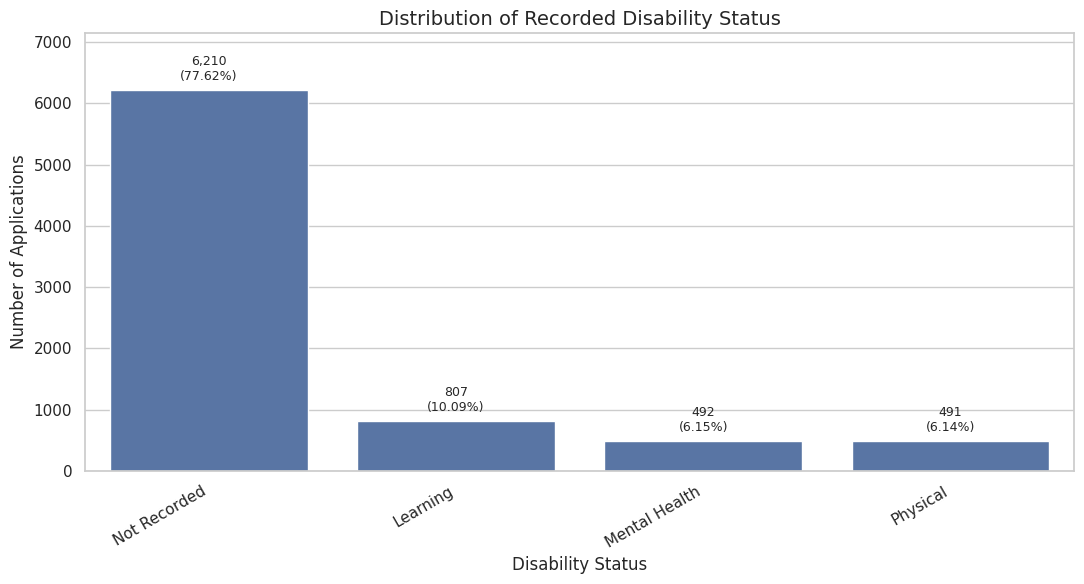

In [ ]:
# Optional EDA 9: Distribution of Recorded Disability Status

# Step 1: Calculate the disability status distribution
disability_distribution = (
    df["disability_status"]
    .value_counts(dropna=False)
    .rename_axis("disability_status")
    .reset_index(name="applications")
)

# Step 2: Calculate percentages
disability_distribution["percentage"] = (
    disability_distribution["applications"] / len(df) * 100
)

# Step 3: Replace NaN with "Not Recorded" for display and plotting
disability_distribution["disability_status"] = (
    disability_distribution["disability_status"]
    .fillna("Not Recorded")
    .astype(str)
)

# Step 4: Display the complete table
print("Distribution of Disability Status:")

display(
    disability_distribution.style.format({
        "applications": "{:,.0f}",
        "percentage": "{:.2f}%"
    })
)

# Step 5: Plot all categories, including missing values
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=disability_distribution,
    x="disability_status",
    y="applications"
)

# Step 6: Add application counts and percentages above each bar
for i, row in disability_distribution.reset_index(drop=True).iterrows():
    ax.annotate(
        f'{row["applications"]:,.0f}\n({row["percentage"]:.2f}%)',
        xy=(i, row["applications"]),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Step 7: Format the graph
plt.title("Distribution of Recorded Disability Status", fontsize=14)
plt.xlabel("Disability Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30, ha="right")

plt.ylim(
    0,
    disability_distribution["applications"].max() * 1.15
)

plt.tight_layout()
plt.show()

### Gender proportion
The gender distribution is examined by calculating the number and percentage of applications across gender categories. Missing values are retained for accurate reporting. A summary table, bar chart and pie chart illustrate applicant representation and provide an overview of gender proportions within the dataset.

,gender,applications,percentage
0,Female,4028,50.35
1,Male,3808,47.60
2,Other,164,2.05


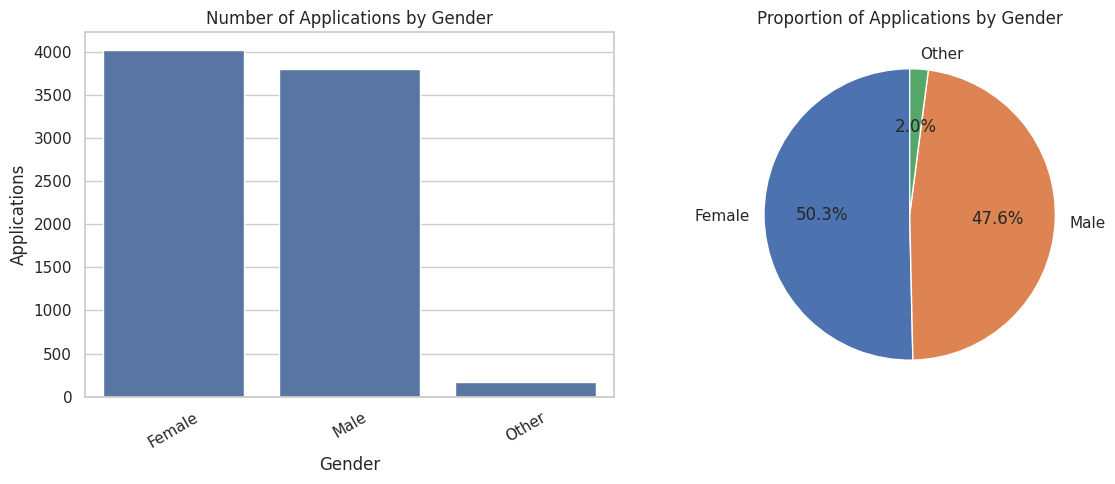

In [ ]:
# EDA 10: Gender distribution

gender_distribution = (
    df["gender"]
    .value_counts(dropna=False)
    .rename_axis("gender")
    .reset_index(name="applications")
)

gender_distribution["percentage"] = (
    gender_distribution["applications"] / len(df) * 100
)

display(gender_distribution.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=gender_distribution,
    x="gender",
    y="applications",
    ax=axes[0]
)

axes[0].set_title("Number of Applications by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Applications")
axes[0].tick_params(axis="x", rotation=30)

axes[1].pie(
    gender_distribution["applications"],
    labels=gender_distribution["gender"].fillna("Missing"),
    autopct="%1.1f%%",
    startangle=90
)

axes[1].set_title("Proportion of Applications by Gender")

plt.tight_layout()
plt.show()

### Places offered by ethnicity
The admission outcomes are analysed across ethnicity groups by calculating application numbers, offers, non-offers and historical offer rates. A summary table presents the results, while bar charts compare the number of offers and offer rates across groups, helping identify variations in historical admission outcomes.

,ethnicity,applications,offers,offer_rate,no_offers
0,Asian,1597,974,60.99,623
1,Black,1593,993,62.34,600
2,Mixed,1614,985,61.03,629
3,Other,1633,974,59.64,659
4,White,1563,924,59.12,639


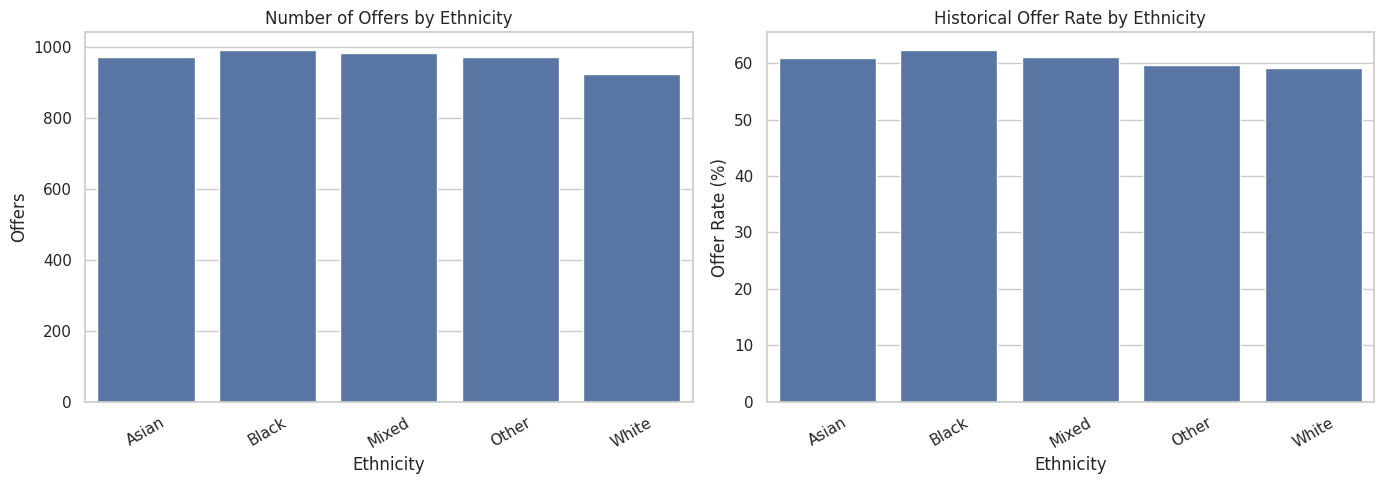

In [ ]:
# EDA 11: Historical offer outcomes by ethnicity

ethnicity_outcomes = (
    df.groupby("ethnicity", dropna=False)["admission_outcome"]
    .agg(
        applications="count",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

ethnicity_outcomes["no_offers"] = (
    ethnicity_outcomes["applications"]
    - ethnicity_outcomes["offers"]
)

ethnicity_outcomes["offer_rate"] *= 100

display(ethnicity_outcomes.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=ethnicity_outcomes,
    x="ethnicity",
    y="offers",
    ax=axes[0]
)

axes[0].set_title("Number of Offers by Ethnicity")
axes[0].set_xlabel("Ethnicity")
axes[0].set_ylabel("Offers")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=ethnicity_outcomes,
    x="ethnicity",
    y="offer_rate",
    ax=axes[1]
)

axes[1].set_title("Historical Offer Rate by Ethnicity")
axes[1].set_xlabel("Ethnicity")
axes[1].set_ylabel("Offer Rate (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Intended subject area by gender
The distribution of applications across intended subject areas is examined by gender. Missing subject-area values are labelled as 'Not recorded' to maintain complete reporting. A grouped bar chart compares application numbers, while a stacked bar chart illustrates gender proportions within each subject area, highlighting differences in applicant distribution.

Application counts by subject area and gender:


gender,Female,Male,Other
intended_subject_area,,,
Arts,1004,947,42
Humanities,1011,938,40
Not recorded,1,0,0
STEM,981,975,41
Social Sciences,1031,948,41


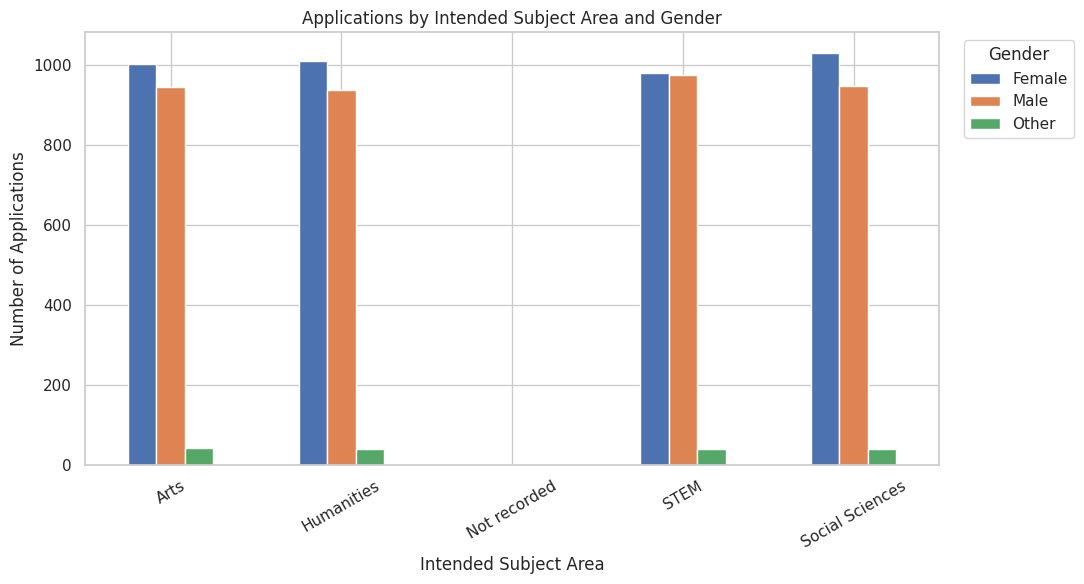

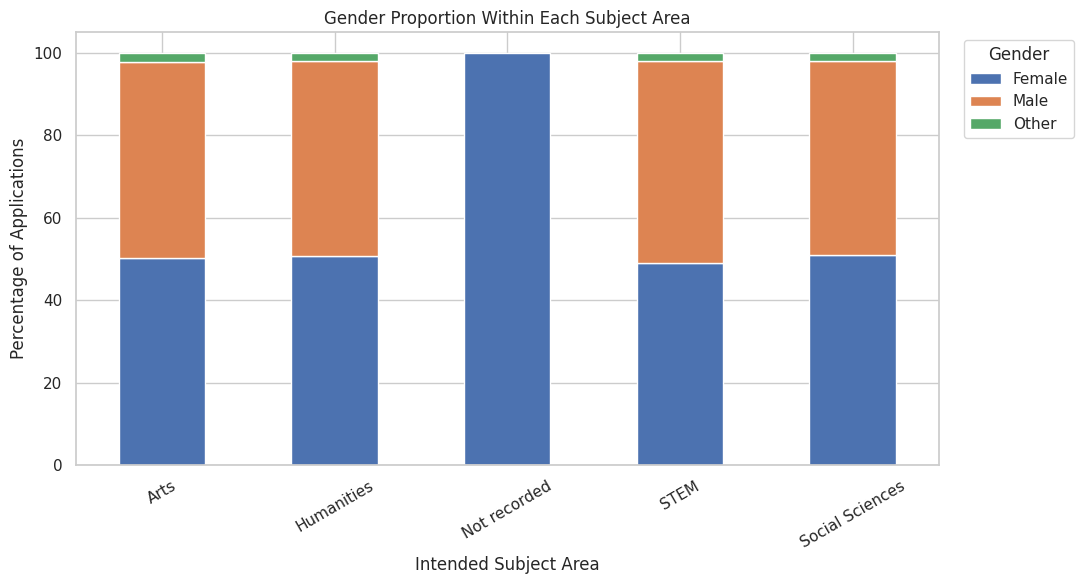

In [ ]:
# EDA 12: Compare subject areas by gender

# Create display copy and label missing subject areas
subject_gender_df = df[
    ["intended_subject_area", "gender"]
].copy()

subject_gender_df["intended_subject_area"] = (
    subject_gender_df["intended_subject_area"]
    .fillna("Not recorded")
)

# Application counts by subject area and gender
subject_gender_counts = pd.crosstab(
    subject_gender_df["intended_subject_area"],
    subject_gender_df["gender"]
)

print("Application counts by subject area and gender:")
display(subject_gender_counts)

# Graph 1: Application counts
subject_gender_counts.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Applications by Intended Subject Area and Gender")
plt.xlabel("Intended Subject Area")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30)
plt.legend(
    title="Gender",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Graph 2: Percentage within each subject area
subject_gender_proportions = (
    pd.crosstab(
        subject_gender_df["intended_subject_area"],
        subject_gender_df["gender"],
        normalize="index"
    ) * 100
)

subject_gender_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Gender Proportion Within Each Subject Area")
plt.xlabel("Intended Subject Area")
plt.ylabel("Percentage of Applications")
plt.xticks(rotation=30)
plt.legend(
    title="Gender",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

### Final EDA summary
The consolidated summary presents the key findings from the exploratory data analysis, including total applications, unique student IDs, admission outcomes and the overall historical offer rate. It also displays recruiter performance, gender outcomes, numerical descriptive statistics and academic score correlation, providing a concise overview of the dataset for business reporting.

In [ ]:
# EDA 13: Consolidated summary for the business report

print("=" * 60)
print("NORTHBRIDGE UNIVERSITY — EDA SUMMARY")
print("=" * 60)

print(f"\nTotal records: {len(df):,}")
print(f"Unique student IDs: {df['student_id'].nunique():,}")

valid_outcomes = df["admission_outcome"].dropna()

print(f"Total offers: {(valid_outcomes == 1).sum():,}")
print(f"Total no offers: {(valid_outcomes == 0).sum():,}")
print(f"Overall offer rate: {valid_outcomes.mean() * 100:.2f}%")

print("\nApplications by recruiter:")
display(recruiter_applications)

print("\nOffer rates by recruiter:")
display(recruiter_offer_rates.round(2))

print("\nOutcomes by gender:")
display(gender_outcomes.round(2))

print("\nMean and median:")
display(descriptive_statistics.round(2))

print("\nAcademic score correlation:")
print(round(correlation, 3))

print("\nEDA calculations and visualisations completed.")

NORTHBRIDGE UNIVERSITY — EDA SUMMARY

Total records: 8,000
Unique student IDs: 8,000
Total offers: 4,850
Total no offers: 3,150
Overall offer rate: 60.62%

Applications by recruiter:


,recruiter,number_of_applications
0,Recruiter A,4000
1,Recruiter B,4000



Offer rates by recruiter:


,recruiter,applications,offers,offer_rate,no_offers
0,Recruiter A,4000,2395,59.88,1605
1,Recruiter B,4000,2455,61.38,1545



Outcomes by gender:


,gender,applications,offers,offer_rate,no_offers
0,Female,4028,2453,60.90,1575
1,Male,3808,2307,60.58,1501
2,Other,164,90,54.88,74



Mean and median:


,Mean,Median
prior_attainment_score,70.00,70.0
admissions_test_score,65.12,65.4
distance_from_campus_km,89.53,79.5



Academic score correlation:
0.014

EDA calculations and visualisations completed.


### Prepare the predictive modelling data

The dataset is prepared for predictive modelling by selecting relevant applicant information, organising numerical and categorical variables, and identifying the admission outcome as the target variable. The predictor and target datasets are created, and missing values and target class distribution are examined to ensure data readiness for model development and evaluation.

### Select appropriate model features
The predictive modelling dataset is prepared by identifying numerical and categorical variables and defining the admission outcome as the target variable. The selected features are separated into predictor and target datasets. Missing predictor values and target class proportions are examined to assess data completeness and identify potential class imbalance before model training.

In [ ]:
# Define numerical and categorical predictors and target variable

numerical_features = [
    "prior_attainment_score",
    "admissions_test_score",
    "personal_statement_score"
]

categorical_features = [
    "intended_subject_area"
]

features = numerical_features + categorical_features
target = "admission_outcome"

# Create predictor and target datasets
X = df[features].copy()
y = df[target].copy()

# Display selected predictors
print("Numerical predictive features:")
print(numerical_features)

print("\nCategorical predictive features:")
print(categorical_features)

print("\nAll predictive features:")
print(features)

print("\nTarget variable:", target)
print("Number of records:", len(X))

# Check missing predictor values
print("\nMissing predictor values:")
display(X.isnull().sum().to_frame("missing_values"))

# Check target class distribution
print("\nTarget class distribution (%):")
display(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Numerical predictive features:
['prior_attainment_score', 'admissions_test_score', 'personal_statement_score']

Categorical predictive features:
['intended_subject_area']

All predictive features:
['prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'intended_subject_area']

Target variable: admission_outcome
Number of records: 8000

Missing predictor values:


,missing_values
prior_attainment_score,4
admissions_test_score,10
personal_statement_score,133
intended_subject_area,1



Target class distribution (%):


,proportion
admission_outcome,
1,60.62
0,39.38


### Create a reproducible 80/20 stratified split
The dataset is divided into 80% training data and 20% testing data using stratified sampling. A fixed random state ensures reproducibility, while stratification maintains the original admission outcome proportions in both datasets. The resulting record counts and offer rates are checked to confirm a consistent distribution.

In [ ]:

# Create a reproducible 80/20 stratified split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining offer rate (%):", round(y_train.mean() * 100, 2))
print("Testing offer rate (%):", round(y_test.mean() * 100, 2))


Training records: 6400
Testing records: 1600

Training offer rate (%): 60.62
Testing offer rate (%): 60.62


### Create the preprocessing pipeline
The preprocessing pipeline prepares numerical and categorical variables for model training. Missing numerical values are replaced using the median, while missing categorical values are filled using the most frequent category. Numerical features are standardised, and categorical variables are converted into numerical representations using one-hot encoding.

In [ ]:

# Create numerical preprocessing pipeline

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Create categorical preprocessing pipeline

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numerical_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Numerical missing values will be imputed using training-set medians.")
print("Categorical missing values will be imputed using the most frequent category.")
print("Numerical features will be standardised.")
print("Categorical features will be one-hot encoded.")


Preprocessing pipeline created successfully.
Numerical missing values will be imputed using training-set medians.
Categorical missing values will be imputed using the most frequent category.
Numerical features will be standardised.
Categorical features will be one-hot encoded.


### Train Logistic Regression
A Logistic Regression model is developed as the baseline classification approach for predicting historical admission outcomes. The preprocessing pipeline is integrated with the classifier to ensure consistent data preparation. The model is trained using the training dataset, with a maximum of 2,000 iterations to support convergence during optimisation.

In [ ]:
# Train Model 1: Logistic Regression baseline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")


Logistic Regression training completed.


### Train Random Forest
A Random Forest classifier is developed as the second predictive model to compare its performance with Logistic Regression. The preprocessing pipeline is integrated with the classifier, using 250 decision trees and a minimum of eight samples per leaf. The model is trained on the same training dataset to ensure a consistent comparison.

In [ ]:
# Train Model 2: Random Forest comparison model

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=250,
                min_samples_leaf=8,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


### Generate test-set predictions and probabilities
Predictions are generated for the testing dataset using both trained classification models. The predicted class labels identify whether each applicant is expected to receive an offer, while predicted probabilities indicate the likelihood of receiving an offer. These outputs are retained for subsequent model evaluation and performance comparison.

In [ ]:
# Generate test-set predictions and predicted probabilities

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

predictions = {}
probabilities = {}

for name, model in models.items():

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(f"{name}: predictions generated.")

Logistic Regression: predictions generated.
Random Forest: predictions generated.


### Evaluate both models using multiple metrics

The performance of Logistic Regression and Random Forest is evaluated using accuracy, precision, recall, F1-score, ROC-AUC and log loss. These metrics assess classification accuracy, prediction reliability, positive-class detection and probability estimation. The results are presented in a comparative table to identify the relative strengths and limitations of both models.

In [ ]:
# Evaluate the two models using multiple metrics

results = []

for name, model in models.items():

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

metrics_df = pd.DataFrame(results)

display(
    metrics_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "ROC-AUC": "{:.3f}",
        "Log Loss": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
0,Logistic Regression,0.614,0.616,0.963,0.751,0.573,0.663
1,Random Forest,0.599,0.622,0.864,0.723,0.557,0.673


### Compare the main classification metrics
The classification performance of both models is visually compared using accuracy, precision, recall, F1-score and ROC-AUC. A grouped bar chart highlights differences across the evaluation metrics, allowing the relative strengths and weaknesses of Logistic Regression and Random Forest to be identified and compared.

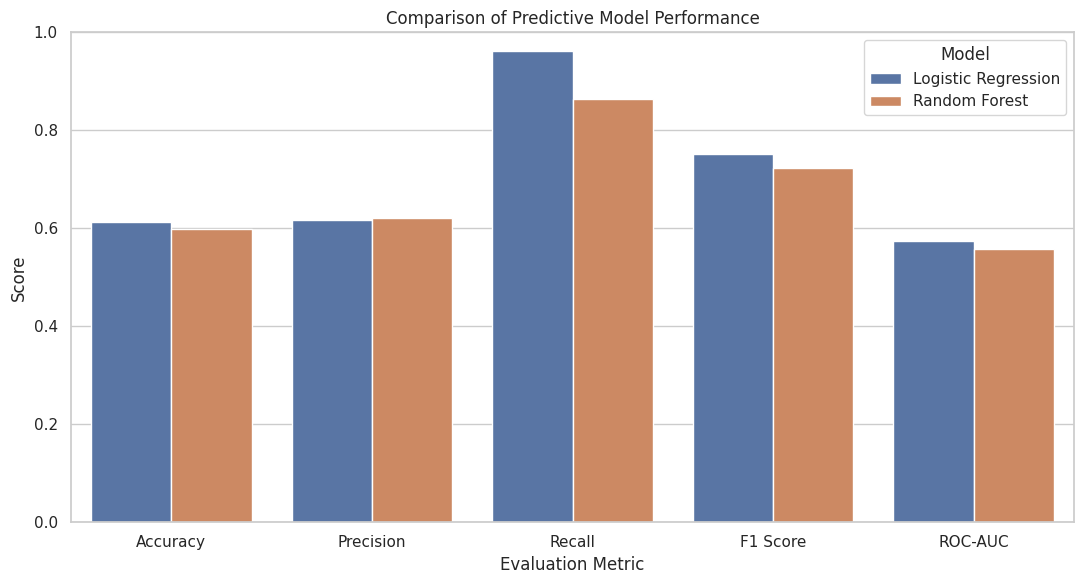

In [ ]:
# Compare the main classification metrics

comparison = metrics_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Comparison of Predictive Model Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### Compare confusion matrices and classification reports
The confusion matrices and classification reports are examined to evaluate the prediction errors made by both models. The confusion matrices identify correct predictions, false positives and false negatives, while the classification reports summarise precision, recall and F1-score for each admission outcome. This comparison helps assess model reliability and identify potential classification weaknesses.

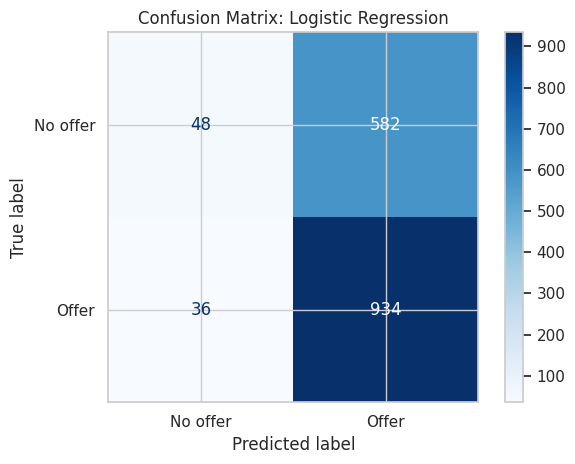


Logistic Regression classification report:
              precision    recall  f1-score   support

    No offer       0.57      0.08      0.13       630
       Offer       0.62      0.96      0.75       970

    accuracy                           0.61      1600
   macro avg       0.59      0.52      0.44      1600
weighted avg       0.60      0.61      0.51      1600



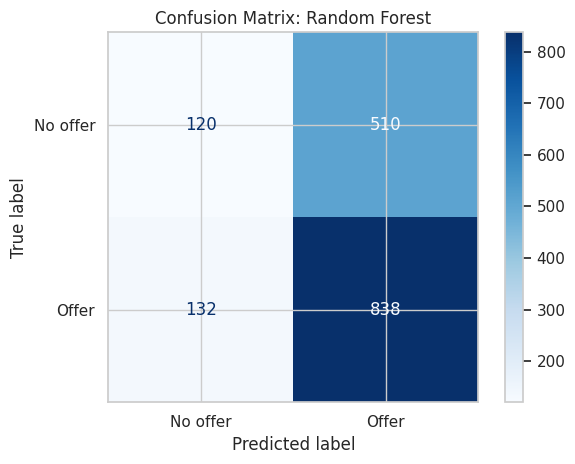


Random Forest classification report:
              precision    recall  f1-score   support

    No offer       0.48      0.19      0.27       630
       Offer       0.62      0.86      0.72       970

    accuracy                           0.60      1600
   macro avg       0.55      0.53      0.50      1600
weighted avg       0.56      0.60      0.55      1600



In [ ]:
# Compare false positives and false negatives

for name in models:

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No offer", "Offer"]
    )

    display_cm.plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

    print(f"\n{name} classification report:")

    print(
        classification_report(
            y_test,
            predictions[name],
            labels=[0, 1],
            target_names=["No offer", "Offer"],
            zero_division=0
        )
    )

### Compare ROC curves
The ROC curves are compared to assess the ability of both models to distinguish between applicants who received offers and those who did not. The AUC values measure overall discriminatory performance, with the diagonal line representing random classification. This comparison helps determine whether either model provides meaningful predictive discrimination.

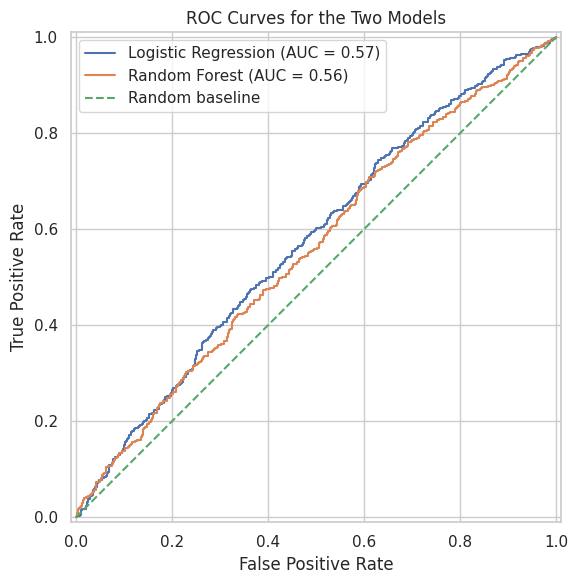

In [ ]:
# Compare discrimination performance

fig, ax = plt.subplots(figsize=(8, 6))

for name in models:

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

ax.set_title("ROC Curves for the Two Models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()

plt.tight_layout()
plt.show()

### Rank models using ROC-AUC and Log Loss
The models are ranked using ROC-AUC and Log Loss to identify the stronger predictive candidate. Higher ROC-AUC and lower Log Loss indicate better performance. Logistic Regression ranks first with an ROC-AUC of 0.573 and Log Loss of 0.663. This is a provisional selection because fairness, interpretability, prediction errors and human oversight must also be considered.

In [ ]:
# Rank models using ROC-AUC and Log Loss

ranked_models = metrics_df.sort_values(
    by=["ROC-AUC", "Log Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(ranked_models)

provisional_model_name = ranked_models.loc[0, "Model"]

print("Provisional model based on the selected metrics:")
print(provisional_model_name)

print(
    "\nThis ranking should also be considered alongside fairness, "
    "interpretability, error costs and human oversight."
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
0,Logistic Regression,0.61375,0.616095,0.962887,0.751408,0.573420,0.662963
1,Random Forest,0.59875,0.621662,0.863918,0.723037,0.556806,0.673409


Provisional model based on the selected metrics:
Logistic Regression

This ranking should also be considered alongside fairness, interpretability, error costs and human oversight.


### Prepare test-set data for fairness auditing
The test dataset is organised with demographic and background information, including gender, ethnicity, disability status, first-generation status, school type and recruiter. Actual admission outcomes, model predictions and predicted probabilities from both classifiers are combined. This enables group-level fairness analysis by comparing predicted outcomes with historical admission decisions.

In [ ]:
# Prepare test-set data for fairness auditing

audit_columns = [
    "gender",
    "ethnicity",
    "disability_status",
    "first_generation_student",
    "school_type",
    "recruiter"
]

audit_test = df.loc[
    X_test.index,
    audit_columns
].copy()

test_results = audit_test.copy()

test_results["actual_offer"] = y_test

test_results["logistic_prediction"] = predictions["Logistic Regression"]
test_results["random_forest_prediction"] = predictions["Random Forest"]

test_results["logistic_probability"] = probabilities["Logistic Regression"]
test_results["random_forest_probability"] = probabilities["Random Forest"]

print("Test results prepared for fairness auditing.")
display(test_results.head())


Test results prepared for fairness auditing.


,gender,ethnicity,disability_status,first_generation_student,school_type,recruiter,actual_offer,logistic_prediction,random_forest_prediction,logistic_probability,random_forest_probability
4696,Male,Other,NaN,1,State,Recruiter B,1,1,1,0.759391,0.845150
685,Female,Black,NaN,0,State,Recruiter A,1,1,1,0.677947,0.611222
4127,Male,Black,NaN,0,State,Recruiter B,1,1,1,0.604492,0.623712
6164,Male,Other,NaN,1,State,Recruiter B,1,0,1,0.469726,0.639796
2536,Male,Asian,Mental Health,1,International,Recruiter A,1,1,1,0.683130,0.571888


### Calculate group-level fairness indicators
Group-level fairness indicators are calculated to examine whether the predictive models produce different admission outcomes across demographic groups. The analysis measures historical offer rates, predicted offer rates, recall and false positive rates. These indicators are calculated separately for Logistic Regression and Random Forest, allowing differences in selection patterns and prediction errors across gender groups to be identified and evaluated.

In [ ]:
# Calculate selection rates and error rates by group

def calculate_group_metrics(data, group_column, prediction_column):

    rows = []

    for group, subset in data.groupby(group_column, dropna=False):

        actual = subset["actual_offer"]
        predicted = subset[prediction_column]

        true_negatives = ((actual == 0) & (predicted == 0)).sum()
        false_positives = ((actual == 0) & (predicted == 1)).sum()

        true_positives = ((actual == 1) & (predicted == 1)).sum()
        false_negatives = ((actual == 1) & (predicted == 0)).sum()

        rows.append({
            "Group": str(group),
            "Applications": len(subset),
            "Historical offer rate (%)": actual.mean() * 100,
            "Predicted offer rate (%)": predicted.mean() * 100,
            "Recall (%)": (
                true_positives / (true_positives + false_negatives) * 100
                if (true_positives + false_negatives) > 0 else np.nan
            ),
            "False positive rate (%)": (
                false_positives / (false_positives + true_negatives) * 100
                if (false_positives + true_negatives) > 0 else np.nan
            )
        })

    return pd.DataFrame(rows)


for prediction_column in [
    "logistic_prediction",
    "random_forest_prediction"
]:

    print(f"\nGender fairness indicators: {prediction_column}")

    gender_fairness = calculate_group_metrics(
        test_results,
        "gender",
        prediction_column
    )

    display(gender_fairness.round(2))


Gender fairness indicators: logistic_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Female,812,60.22,95.07,96.52,92.88
1,Male,757,61.29,94.32,95.91,91.81
2,Other,31,54.84,96.77,100.00,92.86



Gender fairness indicators: random_forest_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Female,812,60.22,84.98,86.09,83.28
1,Male,757,61.29,83.62,86.85,78.50
2,Other,31,54.84,80.65,82.35,78.57


### Audit predicted outcomes across ethnicity groups
The ethnicity-based fairness analysis compares historical and predicted admission outcomes across different ethnic groups. Recall, predicted offer rates and false positive rates are examined separately for both models. The results help identify variations in prediction patterns and potential disparities between groups, supporting a critical assessment of model fairness and the need for appropriate human oversight in admission decisions.

In [ ]:
# Audit predicted outcomes across ethnicity groups

for prediction_column in [
    "logistic_prediction",
    "random_forest_prediction"
]:

    print(f"\nEthnicity fairness audit: {prediction_column}")

    ethnicity_fairness = calculate_group_metrics(
        test_results,
        "ethnicity",
        prediction_column
    )

    display(ethnicity_fairness.round(2))


Ethnicity fairness audit: logistic_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Asian,299,61.87,94.98,97.30,91.23
1,Black,305,64.26,94.43,94.39,94.50
2,Mixed,326,59.82,93.87,94.87,92.37
3,Other,340,58.82,95.88,97.00,94.29
4,White,330,58.79,94.55,97.94,89.71



Ethnicity fairness audit: random_forest_prediction


,Group,Applications,Historical offer rate (%),Predicted offer rate (%),Recall (%),False positive rate (%)
0,Asian,299,61.87,84.62,86.49,81.58
1,Black,305,64.26,80.98,82.14,78.90
2,Mixed,326,59.82,84.36,87.18,80.15
3,Other,340,58.82,84.12,88.50,77.86
4,White,330,58.79,86.97,87.63,86.03


### Code validation, export and maintenance
The final stage focuses on validating the predictive modelling results, exporting important analysis outputs and saving trained model pipelines for future use. Validation checks help ensure data consistency and prediction accuracy. Key findings, model evaluation metrics and fairness audit results are exported into CSV files, while trained pipelines are saved using Joblib to support future testing, maintenance and reproducibility.

### Validate model inputs and predictions
Model validation is performed to ensure that the training and testing datasets contain valid records and binary admission outcomes. The prediction outputs from both models are checked for correct lengths, valid classification labels and probability values between 0 and 1. These checks help identify potential errors and confirm that the models produce consistent outputs before exporting and further analysis.

In [ ]:
# Run basic validation checks

assert len(X_train) + len(X_test) == len(X), (
    "Training and testing sizes do not match the original dataset."
)

assert set(y_train.unique()).issubset({0, 1}), (
    "Training target contains unexpected values."
)

assert set(y_test.unique()).issubset({0, 1}), (
    "Testing target contains unexpected values."
)

for name in models:

    assert len(predictions[name]) == len(y_test), (
        f"Prediction length mismatch for {name}."
    )

    assert np.isfinite(probabilities[name]).all(), (
        f"Invalid predicted probabilities for {name}."
    )

    assert np.all(
        (probabilities[name] >= 0) &
        (probabilities[name] <= 1)
    ), f"Probabilities outside [0, 1] for {name}."

    assert set(np.unique(predictions[name])).issubset({0, 1}), (
        f"Unexpected prediction values for {name}."
    )

print("All basic validation checks passed.")


All basic validation checks passed.


### Export the key analysis results
The analysis results are organised into separate tables, including overall admission summaries, gender outcomes, recruiter application counts, recruiter offer rates and numerical descriptive statistics. Model evaluation metrics and group-level fairness indicators are also consolidated. These results are exported as CSV files into a dedicated output directory, allowing the university to review, share and reuse the findings for future reporting and decision-making.

In [ ]:
# Export the key analysis results

from pathlib import Path

# Create output directory
output_dir = Path("/content/pdm_results")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Overall admission summary
total_applications = len(df)
offers = int(df[target].sum())
non_offers = total_applications - offers

admission_summary = pd.DataFrame({
    "Metric": [
        "Total applications",
        "Offers",
        "Non-offers",
        "Offer rate (%)"
    ],
    "Value": [
        total_applications,
        offers,
        non_offers,
        round(df[target].mean() * 100, 2)
    ]
})

# 2. Gender outcomes
gender_outcomes = (
    df.groupby("gender", dropna=False)[target]
    .agg(
        applications="size",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

gender_outcomes["offer_rate"] *= 100

# 3. Recruiter application counts
recruiter_counts = (
    df.groupby("recruiter", dropna=False)
    .size()
    .reset_index(name="applications")
)

# 4. Recruiter offer rates
recruiter_outcomes = (
    df.groupby("recruiter", dropna=False)[target]
    .agg(
        applications="size",
        offers="sum",
        offer_rate="mean"
    )
    .reset_index()
)

recruiter_outcomes["offer_rate"] *= 100

# 5. Numerical descriptive statistics
descriptive_statistics = (
    df[
        [
            "prior_attainment_score",
            "admissions_test_score",
            "personal_statement_score",
            "distance_from_campus_km"
        ]
    ]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T
    .reset_index(names="variable")
)

# 6. Aggregate fairness audit results
fairness_exports = []

for group_column in [
    "gender",
    "ethnicity",
    "disability_status",
    "first_generation_student",
    "school_type",
    "recruiter"
]:
    for model_name, prediction_column in [
        ("Logistic Regression", "logistic_prediction"),
        ("Random Forest", "random_forest_prediction")
    ]:
        group_results = calculate_group_metrics(
            test_results,
            group_column,
            prediction_column
        )

        group_results.insert(0, "Model", model_name)
        group_results.insert(1, "Audit group", group_column)

        fairness_exports.append(group_results)

fairness_summary = pd.concat(
    fairness_exports,
    ignore_index=True
)

# 7. Define aggregate exports
exports = {
    "admission_summary.csv": admission_summary,
    "gender_outcomes.csv": gender_outcomes,
    "recruiter_application_counts.csv": recruiter_counts,
    "recruiter_offer_rates.csv": recruiter_outcomes,
    "descriptive_statistics.csv": descriptive_statistics,
    "model_evaluation_metrics.csv": metrics_df,
    "fairness_audit_summary.csv": fairness_summary
}

# 8. Save aggregate CSV files
for filename, dataframe in exports.items():

    dataframe.round(6).to_csv(
        output_dir / filename,
        index=False
    )

print("Aggregate analysis results exported successfully.")
print("\nExported files:")

for filename in exports:
    print("-", filename)

Aggregate analysis results exported successfully.

Exported files:
- admission_summary.csv
- gender_outcomes.csv
- recruiter_application_counts.csv
- recruiter_offer_rates.csv
- descriptive_statistics.csv
- model_evaluation_metrics.csv
- fairness_audit_summary.csv


### Save the trained model pipelines
The trained Logistic Regression and Random Forest pipelines are saved using the Joblib library in the designated output directory. Saving the complete pipelines preserves both preprocessing operations and trained model parameters. This allows the models to be reloaded and reused for future testing, predictions and performance evaluation without repeating the entire training process.

In [ ]:
# Save trained pipelines for future testing

import joblib

joblib.dump(
    logistic_model,
    output_dir / "logistic_regression_pipeline.joblib"
)

joblib.dump(
    random_forest_model,
    output_dir / "random_forest_pipeline.joblib"
)

print("Both trained model pipelines have been saved.")


Both trained model pipelines have been saved.


### Summarise the principal findings
The final summary consolidates the main findings from the admissions analysis, including overall application outcomes, recruiter performance and predictive model comparisons. The Logistic Regression and Random Forest models are ranked using ROC-AUC and Log Loss to identify the provisional preferred model. The conclusion also highlights responsible model use, recognising limitations, fairness considerations, interpretability and the importance of human oversight in admission decisions.

In [ ]:
# Summarise the principal findings

print("=" * 65)
print("NORTHBRIDGE UNIVERSITY – ADMISSIONS ANALYSIS")
print("=" * 65)

# 1. Overall admission summary
print(f"Applications analysed: {len(df):,}")
print(f"Historical offers: {int(df[target].sum()):,}")
print(f"Historical rejections: {len(df) - int(df[target].sum()):,}")
print(f"Historical offer rate: {df[target].mean() * 100:.2f}%")

# 2. Applications by recruiter
print("\nApplications by recruiter:")
print(recruiter_counts.to_string(index=False))

# 3. Historical offer rates by recruiter
print("\nHistorical offer rates by recruiter:")
print(recruiter_outcomes.round(2).to_string(index=False))

# 4. Model comparison
print("\nModel comparison:")
print(metrics_df.round(4).to_string(index=False))

# 5. Provisional model ranking
print("\nProvisional model ranking:")

print(
    ranked_models[
        ["Model", "ROC-AUC", "Log Loss"]
    ].round(4).to_string(index=False)
)

print("\nProvisional model based on selected metrics:")
print(provisional_model_name)

# 6. Responsible-use conclusion
print("\nResponsible-use conclusion:")

print(
    "Predictions describe historical admission decisions, not future "
    "academic success. Model performance is limited by the available "
    "predictors and must be considered alongside fairness, "
    "interpretability, error costs and human oversight."
)

print("\n" + "=" * 65)
print("ANALYSIS COMPLETED")
print("=" * 65)


NORTHBRIDGE UNIVERSITY – ADMISSIONS ANALYSIS
Applications analysed: 8,000
Historical offers: 4,850
Historical rejections: 3,150
Historical offer rate: 60.62%

Applications by recruiter:
  recruiter  applications
Recruiter A          4000
Recruiter B          4000

Historical offer rates by recruiter:
  recruiter  applications  offers  offer_rate
Recruiter A          4000    2395       59.88
Recruiter B          4000    2455       61.38

Model comparison:
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  Log Loss
Logistic Regression    0.6138     0.6161  0.9629    0.7514   0.5734    0.6630
      Random Forest    0.5988     0.6217  0.8639    0.7230   0.5568    0.6734

Provisional model ranking:
              Model  ROC-AUC  Log Loss
Logistic Regression   0.5734    0.6630
      Random Forest   0.5568    0.6734

Provisional model based on selected metrics:
Logistic Regression

Responsible-use conclusion:
Predictions describe historical admission decisions, not future aca